# Amazon Reviews 2023 - Beauty Category - Sentiment Analysis

This notebook builds a clean, unbiased, and reproducible pipeline for a
sentiment analysis project on the **All Beauty** subset of the
Amazon Reviews 2023 dataset (https://amazon-reviews-2023.github.io/).

**Pipeline overview:**
1. Install & import libraries
2. Load reviews + metadata
3. Merge datasets and create the sentiment target
4. Clean the merged dataframe (drop leakage/unneeded columns, duplicates, nulls)
5. Draw a stratified (unbiased) sample from the full dataset
6. Split into train / validation / test (stratified)
7. Exploratory Data Analysis (EDA)
8. Text preprocessing - two separate pipelines:
   - Classical ML pipeline (TF-IDF based models)
   - Transformer pipeline (DistilBERT / BERT / RoBERTa)
9. Preparing data for a transformer model (tokenization)


## 1. Install & import required libraries

In [ ]:
# Install dependencies for the classical ML / EDA pipeline (TF-IDF models, plotting, NLTK)
!pip install -q scikit-learn nltk wordcloud matplotlib seaborn

### 1.1 Install the deep learning / Transformers stack

This project is **text-only** (no images or video), so we deliberately remove
`torchvision` and `torchaudio`. Keeping them installed alongside a different
`torch` build is a common source of import errors in Colab (e.g. the
`datasets` library trying to import `torchvision.io.VideoReader` while
converting batches to tensors, or `torch`/`torchvision` binary-ABI
mismatches). We keep the `torch` build that Colab ships with (already
matched to the runtime's CUDA version) and only install the Hugging Face
NLP stack on top of it, all in a **single `pip install` command** so pip's
dependency resolver picks one consistent, compatible set of versions for
`numpy`, `pyarrow`, `huggingface_hub`, etc., instead of us pinning each
package separately (manual pinning is what caused repeated binary
incompatibility errors during development).

In [ ]:
# We don't need torchvision/torchaudio for a text-only pipeline; removing them
# avoids the datasets/torchvision import conflict described above.
!pip uninstall -y -q torchvision torchaudio

# Install (or upgrade) the Hugging Face stack in one shot so all packages
# resolve to mutually compatible versions.
!pip install -q -U \
    transformers \
    datasets \
    accelerate \
    evaluate \
    tokenizers \
    huggingface_hub \
    sentencepiece

import os

# IMPORTANT: set these environment variables before importing transformers.
# Without USE_TF=0, transformers also tries to import a TensorFlow backend,
# which can conflict with the numpy version installed in Colab. We only use
# PyTorch, so we explicitly disable the TensorFlow import path.
os.environ["USE_TF"] = "0"
os.environ["USE_TORCH"] = "1"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"

import sys
import torch
import numpy as np
import pandas as pd

import transformers
import datasets
import accelerate
import tokenizers
import evaluate

print("Python:", sys.version)
print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Evaluate:", evaluate.__version__)
print("NumPy:", np.__version__)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 774.9/774.9 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 17.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
timm 1.0.28 requires torchvision, which is not installed.
Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Torch: 2.11.0+cu128 | CUDA available: True
Transformers: 5.14.1
Datasets: 5.0.1
Accelerate: 1.14.0
Tokenizers: 0.22.2
Evaluate: 0.4.6
NumPy: 2.0.2
Using device: cuda


In [ ]:
# Core libraries
import re
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# ML
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Download NLTK resources (only needed once)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)


## 2. Load the reviews dataset (All Beauty)

In [ ]:
# Strategy note: instead of relying on `load_dataset` with this dataset's
# legacy loading script (support for which was dropped in recent `datasets`
# versions and was the root cause of repeated errors), we fetch the raw
# reviews file (JSONL) directly from the repo via huggingface_hub. This
# approach does not depend on the `datasets` version at all, so it works
# reliably across environments and library versions.
import json as _json
from huggingface_hub import hf_hub_download

review_file_path = hf_hub_download(
    repo_id="McAuley-Lab/Amazon-Reviews-2023",
    filename="raw/review_categories/All_Beauty.jsonl",
    repo_type="dataset",
)

review_records = []
with open(review_file_path, "r", encoding="utf-8") as f:
    for line in f:
        review_records.append(_json.loads(line))

# Quick look at a single example
print(review_records[0])


{'rating': 5.0, 'title': 'Such a lovely scent but not overpowering.', 'text': "This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like you need a lot of it though to get the texture I want. I have a lot of hair, medium thickness. I am comparing to other brands with yucky chemicals so I'm gonna stick with this. Try it!", 'images': [], 'asin': 'B00YQ6X8EO', 'parent_asin': 'B00YQ6X8EO', 'user_id': 'AGKHLEW2SOWHNMFQIJGBECAF7INQ', 'timestamp': 1588687728923, 'helpful_vote': 0, 'verified_purchase': True}


In [ ]:
df = pd.DataFrame(review_records)
print("Reviews shape:", df.shape)
df.head(3)

Reviews shape: (701528, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True


## 3. Load the metadata dataset (product info) and merge

In [ ]:
# Note: unlike the reviews file (still raw JSONL), the metadata file for
# All_Beauty has been converted to Parquet in the repo. `pd.read_parquet`
# with a wildcard ("*") path does not work directly with `hf://` URLs
# (pyarrow cannot glob them on its own), so we use `HfFileSystem` to first
# resolve the actual shard filenames, then read and concatenate them.
from huggingface_hub import HfFileSystem

fs = HfFileSystem()
meta_parquet_files = fs.glob(
    "datasets/McAuley-Lab/Amazon-Reviews-2023/raw_meta_All_Beauty/full-*.parquet"
)
print("Found metadata shards:", meta_parquet_files)

meta_dfs = [pd.read_parquet(fs.open(f)) for f in meta_parquet_files]
df_meta = pd.concat(meta_dfs, ignore_index=True)
print("Metadata shape (before dedup):", df_meta.shape)


Found metadata shards: ['datasets/McAuley-Lab/Amazon-Reviews-2023/raw_meta_All_Beauty/full-00000-of-00001.parquet']
Metadata shape (before dedup): (112590, 16)


In [ ]:
# FIX #1: the metadata table can have multiple rows for the same parent_asin.
# If we merge without deduplicating first, review rows get duplicated during the
# left join, which silently inflates the dataset and biases any downstream sample.
n_dup_products = df_meta["parent_asin"].duplicated().sum()
print("Duplicated parent_asin rows in metadata:", n_dup_products)

df_meta = df_meta.drop_duplicates(subset="parent_asin", keep="first")
print("Metadata shape (after dedup):", df_meta.shape)


Duplicated parent_asin rows in metadata: 0
Metadata shape (after dedup): (112590, 16)


In [ ]:
# Merge reviews with product metadata on parent_asin
merged_df = pd.merge(df, df_meta, on="parent_asin", how="left")
print("Merged shape:", merged_df.shape)

# Sanity check: merged row count should equal the original reviews row count
# now that metadata duplicates were removed.
assert merged_df.shape[0] == df.shape[0], "Merge produced extra rows - check for duplicate keys."


Merged shape: (701528, 25)


In [ ]:
# Create 3-class sentiment labels from ratings
sentiment_mapping = {
    1.0: "Negative",
    2.0: "Negative",
    3.0: "Neutral",
    4.0: "Positive",
    5.0: "Positive"
}

# Apply mapping
merged_df["sentiment"] = merged_df["rating"].map(sentiment_mapping)

# Check distribution
print("Class Distribution:")
print(merged_df["sentiment"].value_counts())

print("\nPercentage:")
print((merged_df["sentiment"].value_counts(normalize=True) * 100).round(2))


Class Distribution:
sentiment
Positive    500107
Negative    145114
Neutral      56307
Name: count, dtype: int64

Percentage:
sentiment
Positive    71.29
Negative    20.69
Neutral      8.03
Name: proportion, dtype: float64


## 4. Cleaning the merged dataframe



In [ ]:
# Merge review title and review text into a single text column
merged_df["review"] = (
    merged_df["title_x"].fillna("").astype(str)
    + " "
    + merged_df["text"].fillna("").astype(str)
)


In [ ]:
# Drop columns that are not useful for sentiment analysis
columns_to_drop = [
    "images_x",
    "asin",
    "parent_asin",
    "user_id",
    "timestamp",
    "images_y",
    "videos",
    "categories",
    "bought_together",
    "subtitle",
    "author",
    "title_x",
    "text",
]
merged_df.drop(columns=columns_to_drop, inplace=True)
print(merged_df.columns.tolist())


['rating', 'helpful_vote', 'verified_purchase', 'main_category', 'title_y', 'average_rating', 'rating_number', 'features', 'description', 'price', 'store', 'details', 'sentiment', 'review']


In [ ]:
# Drop rows with an empty review after merging title + text
before = merged_df.shape[0]
merged_df = merged_df[
    merged_df["review"].notna() & (merged_df["review"].str.strip() != "")
].copy()
print(f"Dropped {before - merged_df.shape[0]} rows with empty reviews.")


Dropped 0 rows with empty reviews.


In [ ]:
# Remove duplicate reviews (exact text duplicates, e.g. copy-pasted or spam reviews)
before = merged_df.shape[0]
merged_df.drop_duplicates(subset=["review"], inplace=True)
print(f"Dropped {before - merged_df.shape[0]} duplicate reviews.")


Dropped 29904 duplicate reviews.


In [ ]:
# Remove reviews that are too short to carry sentiment information (< 3 words)
before = merged_df.shape[0]
merged_df = merged_df[merged_df["review"].str.split().str.len() >= 3].copy()
print(f"Dropped {before - merged_df.shape[0]} reviews shorter than 3 words.")


Dropped 2776 reviews shorter than 3 words.


In [ ]:
# Check remaining missing values
merged_df.isnull().sum().sort_values(ascending=False)


,0
store,46889
rating,0
verified_purchase,0
main_category,0
title_y,0
helpful_vote,0
average_rating,0
rating_number,0
description,0
features,0


In [ ]:
# 'store' has too many missing values and is not useful for sentiment analysis
merged_df.drop(columns=["store"], inplace=True)


In [ ]:
# FIX #3: price was stored as an object (mixed types like the string "None").
# Convert to numeric and inspect how many values are missing.
merged_df["price"] = pd.to_numeric(merged_df["price"], errors="coerce")
print("Missing price values:", merged_df["price"].isnull().sum())

# price is not relevant to sentiment and has too many missing values -> drop it
merged_df.drop(columns=["price"], inplace=True)


Missing price values: 492294


In [ ]:
print(merged_df.columns.tolist())
print(merged_df.shape)
merged_df.isnull().sum()


['rating', 'helpful_vote', 'verified_purchase', 'main_category', 'title_y', 'average_rating', 'rating_number', 'features', 'description', 'details', 'sentiment', 'review']
(668848, 12)


,0
rating,0
helpful_vote,0
verified_purchase,0
main_category,0
title_y,0
average_rating,0
rating_number,0
features,0
description,0
details,0


In [ ]:
merged_df.head()

,rating,helpful_vote,verified_purchase,main_category,title_y,average_rating,rating_number,features,description,details,sentiment,review
0,5.0,0,True,All Beauty,Herbivore - Natural Sea Mist Texturizing Salt ...,4.3,384,[],"[If given the choice, weÕd leave most telltale...","{""Hair Type"": ""Wavy"", ""Material Type Free"": ""D...",Positive,Such a lovely scent but not overpowering. This...
1,4.0,1,True,All Beauty,All Natural Vegan Dry Shampoo Powder - Eco Fri...,4.0,56,[],[],"{""Brand"": ""Two Goats Apothecary"", ""Item Form"":...",Positive,Works great but smells a little weird. This pr...
2,5.0,2,True,All Beauty,New Road Beauty - Creamsicle - Variety 3 Pack ...,4.4,699,"[Same Great Product, NEW PACKAGING., MOISTURIZ...",[New Road Beauty Paraffin Wax is recommended f...,"{""Package Dimensions"": ""10.5 x 6.4 x 1.6 inche...",Positive,"Yes! Smells good, feels great!"
3,1.0,0,True,All Beauty,muaowig Ombre Body Wave Bundles 1B Grey Human ...,1.0,1,[?Hair Bundle Material?:Brazilian Virgin Human...,[Hair Material: Brazilian Virgin Human Hair Bu...,"{""Brand"": ""muaowig"", ""Material"": ""Human Hair"",...",Negative,Synthetic feeling Felt synthetic
4,5.0,0,True,All Beauty,Yinhua Electric Nail Drill Kit Portable Profes...,3.5,20,[],[],"{""Package Dimensions"": ""8.5 x 3.82 x 2.24 inch...",Positive,A+ Love it


## 5. Draw an unbiased (stratified) sample

The full dataset has ~600K+ rows and is heavily imbalanced (Very Positive ~59%,
Negative ~6%). To keep a manageable, representative sample, we use
**stratified sampling**: the class proportions in the sample match the
proportions in the full dataset, so the sample is not biased toward any
particular sentiment.


In [ ]:
SAMPLE_SIZE = 100_000  # adjust based on available compute

sample_df, _ = train_test_split(
    merged_df,
    train_size=SAMPLE_SIZE,
    stratify=merged_df["sentiment"],
    random_state=RANDOM_STATE
)

print("Full dataset proportions:")
print(merged_df["sentiment"].value_counts(normalize=True) * 100)
print("\nSample proportions:")
print(sample_df["sentiment"].value_counts(normalize=True) * 100)


Full dataset proportions:
sentiment
Positive    70.538000
Negative    21.245485
Neutral      8.216516
Name: proportion, dtype: float64

Sample proportions:
sentiment
Positive    70.538
Negative    21.245
Neutral      8.217
Name: proportion, dtype: float64


## 6. Train / Validation / Test split (stratified)

In [ ]:
train_df, temp_df = train_test_split(
    sample_df,
    test_size=0.30,
    stratify=sample_df["sentiment"],
    random_state=RANDOM_STATE
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["sentiment"],
    random_state=RANDOM_STATE
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


Train: (70000, 12)
Validation: (15000, 12)
Test: (15000, 12)


## 7. Exploratory Data Analysis (EDA)

Every plot here is meant to inform a concrete decision later on (class
balancing strategy, model input length, feature quality, etc.), not just for
display.


### 7.1 Class distribution (target balance)

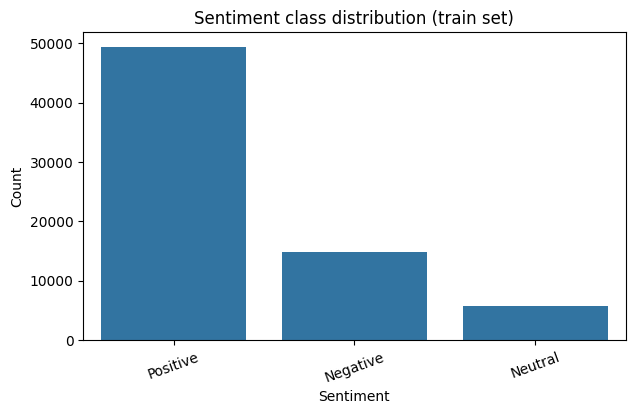

,proportion
sentiment,
Positive,70.538571
Negative,21.244286
Neutral,8.217143


In [ ]:
plt.figure(figsize=(7, 4))
order = train_df["sentiment"].value_counts().index
sns.countplot(data=train_df, x="sentiment", order=order)
plt.title("Sentiment class distribution (train set)")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

train_df["sentiment"].value_counts(normalize=True) * 100


### 7.2 Review length distribution per class

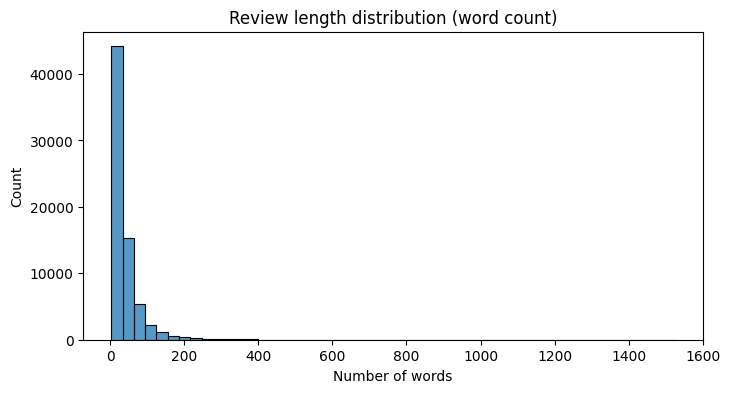

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,14871.0,36.319077,40.411244,3.0,13.0,25.0,45.0,1424.0
Neutral,5752.0,44.440195,54.800315,3.0,16.0,31.0,53.0,1298.0
Positive,49377.0,37.819086,48.875219,3.0,11.0,23.0,45.0,1525.0


In [ ]:
train_df["review_len"] = train_df["review"].str.split().str.len()

plt.figure(figsize=(8, 4))
sns.histplot(data=train_df, x="review_len", bins=50)
plt.title("Review length distribution (word count)")
plt.xlabel("Number of words")
plt.show()

train_df.groupby("sentiment")["review_len"].describe()


### 7.3 Most frequent words per sentiment class

In [ ]:
from collections import Counter

stop_words = set(stopwords.words("english"))

def get_top_words(text_series, n=15):
    words = " ".join(text_series.astype(str)).lower().split()
    words = [w for w in words if w.isalpha() and w not in stop_words]
    return Counter(words).most_common(n)

for label in train_df["sentiment"].unique():
    subset = train_df[train_df["sentiment"] == label]["review"]
    print(f"--- Top words for: {label} ---")
    print(get_top_words(subset))
    print()


--- Top words for: Positive ---
[('great', 16852), ('love', 15557), ('hair', 11928), ('good', 9721), ('like', 9378), ('product', 8944), ('use', 8063), ('really', 6197), ('works', 5491), ('one', 5467), ('easy', 5256), ('nice', 5145), ('stars', 5017), ('skin', 4806), ('would', 4671)]

--- Top words for: Neutral ---
[('like', 1717), ('hair', 1483), ('good', 1191), ('product', 998), ('use', 959), ('would', 922), ('get', 840), ('one', 787), ('really', 769), ('stars', 689), ('great', 679), ('three', 662), ('little', 595), ('nice', 575), ('much', 530)]

--- Top words for: Negative ---
[('hair', 3762), ('like', 3535), ('one', 2668), ('product', 2630), ('would', 1949), ('get', 1790), ('use', 1719), ('work', 1607), ('good', 1490), ('waste', 1484), ('even', 1469), ('buy', 1415), ('money', 1390), ('used', 1157), ('really', 1107)]



### 7.4 verified_purchase vs sentiment

In [ ]:
pd.crosstab(
    train_df["verified_purchase"], train_df["sentiment"], normalize="index"
) * 100


sentiment,Negative,Neutral,Positive
verified_purchase,,,
False,16.41726,8.223159,75.359582
True,21.77068,8.216487,70.012833


### 7.5 helpful_vote vs sentiment

In [ ]:
train_df.groupby("sentiment")["helpful_vote"].describe()


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,14871.0,0.850918,3.355315,0.0,0.0,0.0,1.0,151.0
Neutral,5752.0,0.715751,2.678127,0.0,0.0,0.0,1.0,77.0
Positive,49377.0,1.011078,6.462253,0.0,0.0,0.0,1.0,646.0


### 7.8 main_category vs sentiment (visual)

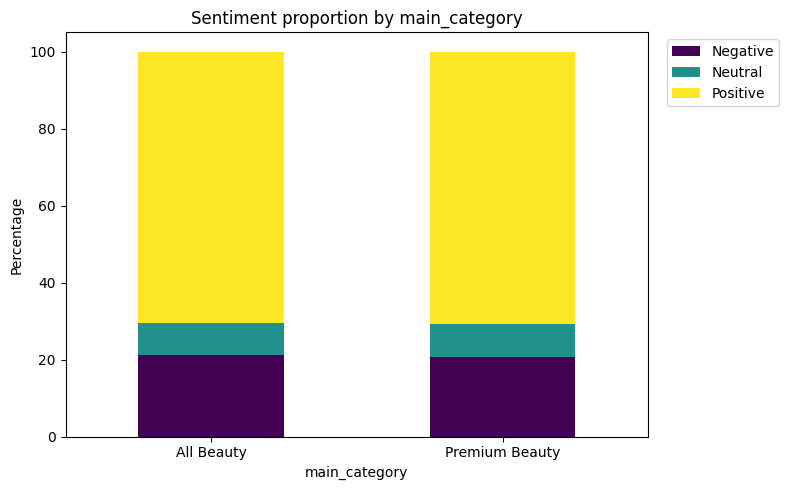

,count
main_category,
All Beauty,69286
Premium Beauty,714


In [ ]:
cross = pd.crosstab(train_df["main_category"], train_df["sentiment"], normalize="index") * 100

cross.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.title("Sentiment proportion by main_category")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

train_df["main_category"].value_counts()


### 7.9 Emoji presence check

Emojis can carry strong sentiment signal. We check how common they are before
deciding whether to strip them (classical ML) or keep them (transformer
pipeline, where they can still add signal).


In [ ]:
import re as _re

emoji_pattern = _re.compile(
    "["
    "\U0001F300-\U0001FAFF"
    "\U00002700-\U000027BF"
    "\U00002600-\U000026FF"
    "]+",
    flags=_re.UNICODE
)

train_df["has_emoji"] = train_df["review"].astype(str).apply(lambda t: bool(emoji_pattern.search(t)))
print("Reviews containing emoji:", train_df["has_emoji"].sum(), f"({train_df['has_emoji'].mean()*100:.2f}%)")

pd.crosstab(train_df["has_emoji"], train_df["sentiment"], normalize="index") * 100


Reviews containing emoji: 1873 (2.68%)


sentiment,Negative,Neutral,Positive
has_emoji,,,
False,21.327814,8.306545,70.365641
True,18.206086,4.965296,76.828617


### 7.10 Neutral vs neighboring classes - word overlap check

If Neutral shares most of its top words with Positive/Negative, the language
boundary between classes is weak, and merging into 3 classes
(Negative / Neutral / Positive) may give a stronger, more learnable model.


In [ ]:
neutral_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Neutral"]["review"], n=30))
positive_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Positive"]["review"], n=30))
negative_words = set(w for w, _ in get_top_words(train_df[train_df["sentiment"] == "Negative"]["review"], n=30))

print("Overlap Neutral/Positive:", neutral_words & positive_words)
print("Overlap Neutral/Negative:", neutral_words & negative_words)


Overlap Neutral/Positive: {'works', 'using', 'stars', 'use', 'get', 'good', 'used', 'hair', 'like', 'well', 'would', 'great', 'nice', 'love', 'skin', 'product', 'much', 'little', 'really', 'one'}
Overlap Neutral/Negative: {'color', 'product', 'really', 'work', 'hair', 'use', 'get', 'one', 'much', 'like', 'good', 'used', 'would'}


## 8. Text preprocessing

Preprocessing is **not one-size-fits-all**. We build two separate cleaning
pipelines depending on which model family will consume the text:

- **Classical ML (TF-IDF + Logistic Regression / SVM / Naive Bayes)**:
  needs aggressive normalization - lowercasing, punctuation removal,
  stopword removal, lemmatization. These models only see word frequencies,
  so removing noise words and merging word forms helps a lot.

- **Transformer models (DistilBERT / BERT / RoBERTa)**:
  needs light cleaning only - keep punctuation, casing information and
  stopwords, since the model's own subword tokenizer and attention
  mechanism already handle context, negation and word forms. Aggressive
  cleaning here actually *hurts* performance.


### 8.1 Shared basic cleaning (applies to both pipelines)

In [ ]:
def basic_clean(text):
    """Light cleaning shared by every pipeline: remove links, HTML tags,
    and collapse extra whitespace. Keeps punctuation and casing intact."""
    text = re.sub(r"http\S+|www\S+", " ", text)   # URLs
    text = re.sub(r"<.*?>", " ", text)               # HTML tags
    text = re.sub(r"\s+", " ", text).strip()         # extra whitespace
    return text

for split_df in [train_df, val_df, test_df]:
    split_df["review_basic"] = split_df["review"].apply(basic_clean)


### 8.2 Classical ML preprocessing (TF-IDF pipeline)

In [ ]:
lemmatizer = WordNetLemmatizer()

def clean_for_classical_ml(text):
    """Aggressive cleaning for TF-IDF based models:
    lowercase -> remove punctuation/numbers -> remove stopwords -> lemmatize."""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)            # keep letters only
    text = re.sub(r"\s+", " ", text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words]
    return " ".join(tokens)

for split_df in [train_df, val_df, test_df]:
    split_df["review_clf_ml"] = split_df["review_basic"].apply(clean_for_classical_ml)

train_df[["review", "review_clf_ml"]].head(3)


,review,review_clf_ml
538835,Glam lash I love them. They are easy to use. O...,glam lash love easy use thing keen liquid line...
338362,Good product however a little overpriced It is...,good product however little overpriced fair pr...
440001,Nice product Color is light. But easy to use,nice product color light easy use


### 8.3 Transformer preprocessing (DistilBERT / BERT / RoBERTa)

Only the shared basic cleaning (`review_basic`) is used here - no stopword
removal, no lemmatization, casing and punctuation are preserved. The model's
own tokenizer will handle subword splitting.


In [ ]:
# The transformer-ready text is simply the lightly cleaned version
for split_df in [train_df, val_df, test_df]:
    split_df["review_transformer"] = split_df["review_basic"]

train_df[["review", "review_transformer"]].head(3)


,review,review_transformer
538835,Glam lash I love them. They are easy to use. O...,Glam lash I love them. They are easy to use. O...
338362,Good product however a little overpriced It is...,Good product however a little overpriced It is...
440001,Nice product Color is light. But easy to use,Nice product Color is light. But easy to use


## 9. Fine-tuning RoBERTa-base for Sentiment Classification

We now use the `review_transformer` column prepared above (`train_df`,
`val_df`, `test_df`) to fine-tune a **roberta-base** model as a sequence
classifier on the 3 sentiment classes defined earlier
(Negative / Neutral / Positive).

**Steps:**
1. Install & import the required libraries (transformers, datasets, torch, evaluate).
2. Label-encode the `sentiment` column.
3. Load the tokenizer and tokenize all 3 splits.
4. Load the RoBERTa classification model (one output per class).
5. Compute class weights to handle the imbalance observed in the EDA.
6. Define `compute_metrics` (accuracy + macro F1 + per-class report).
7. Build `TrainingArguments` + a weighted `Trainer` + train.
8. Final evaluation on the test set + comparison with the classical ML baseline.
9. Save the model and tokenizer.

### 9.1 Install & import the extra libraries needed for the transformer pipeline

> All required packages (transformers, accelerate, datasets, evaluate,
> tokenizers) were already installed in the consolidated setup cell at the
> top of the notebook (section 1.1). The next cell only imports what's
> needed for this section - no extra `pip install` here.

In [ ]:
# transformers / datasets / accelerate / evaluate / tokenizers, and the
# TensorFlow-avoidance environment variables, were already installed and
# configured in the consolidated setup cell at the top of the notebook.
# Here we only import the additional classes needed specifically for
# fine-tuning (Dataset, model/trainer classes, sklearn metrics).
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

print("Using device:", device)


Using device: cuda


### 9.2 Label encoding

RoBERTa expects integer labels, not text, so we convert the `sentiment`
column to numeric IDs and keep the mapping around so we can decode
predictions back to readable labels later.

In [ ]:
# We use LabelEncoder. Best practice would be to fit only on the train set
# to avoid any leakage from val/test, but since the classes are fixed and
# known in advance (3 values), we fit on the full label set here to
# guarantee an identical mapping across all three splits.

label_encoder = LabelEncoder()
label_encoder.fit(train_df["sentiment"])

# This is the mapping we'll use later to decode predictions (index -> label name)
id2label = {i: label for i, label in enumerate(label_encoder.classes_)}
label2id = {label: i for i, label in id2label.items()}

print("id2label:", id2label)

# Add a numeric label column to each split
for split_df in [train_df, val_df, test_df]:
    split_df["label"] = label_encoder.transform(split_df["sentiment"])

NUM_LABELS = len(id2label)
print("Number of classes:", NUM_LABELS)


id2label: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
Number of classes: 3


### 9.3 Tokenizer

We load the RoBERTa tokenizer and set `MAX_LENGTH` based on the review
length distribution seen in the EDA (cell 31) instead of an arbitrary
number.

In [ ]:
MODEL_NAME = "roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Compute the 95th percentile of review length (in words) to pick a sensible
# max_length - long enough to avoid truncating most reviews, short enough to
# avoid wasting compute on unnecessary padding.
review_len_95 = int(train_df["review_transformer"].str.split().str.len().quantile(0.95))
print("95th percentile of review length (words):", review_len_95)

# RoBERTa's hard limit is 512 tokens, so we pick the closest practical value
# (power of 2) that doesn't exceed it.
MAX_LENGTH = min(256, max(64, review_len_95))
print("Chosen MAX_LENGTH:", MAX_LENGTH)


95th percentile of review length (words): 114
Chosen MAX_LENGTH: 114


### 9.4 Building HuggingFace `Dataset` objects + Tokenization

In [ ]:
# Convert each DataFrame (train/val/test) into a HuggingFace Dataset so we
# can use .map() efficiently (batched processing) together with the Trainer
# API later on.

# Keep only the columns we actually need: the processed text + the label
train_ds = Dataset.from_pandas(train_df[["review_transformer", "label"]].reset_index(drop=True))
val_ds = Dataset.from_pandas(val_df[["review_transformer", "label"]].reset_index(drop=True))
test_ds = Dataset.from_pandas(test_df[["review_transformer", "label"]].reset_index(drop=True))


def tokenize_function(batch):
    # truncation=True: any review longer than MAX_LENGTH gets truncated.
    # Padding is left to the DataCollator (dynamic padding) instead of being
    # applied here, which saves compute during training.
    return tokenizer(
        batch["review_transformer"],
        truncation=True,
        max_length=MAX_LENGTH,
    )


train_ds = train_ds.map(tokenize_function, batched=True)
val_ds = val_ds.map(tokenize_function, batched=True)
test_ds = test_ds.map(tokenize_function, batched=True)

# The Trainer API expects a column named "labels", not "label"
train_ds = train_ds.rename_column("label", "labels")
val_ds = val_ds.rename_column("label", "labels")
test_ds = test_ds.rename_column("label", "labels")

# Drop the raw text column now that tokenization is done (no longer needed for training)
train_ds = train_ds.remove_columns(["review_transformer"])
val_ds = val_ds.remove_columns(["review_transformer"])
test_ds = test_ds.remove_columns(["review_transformer"])

# Set the format to PyTorch tensors
train_ds.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
val_ds.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
test_ds.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])

print(train_ds)


Map:   0%|          | 0/70000 [00:00<?, ? examples/s]

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 70000
})


### 9.5 Data collator (dynamic padding)

In [ ]:
# DataCollatorWithPadding pads each batch only up to the longest sequence in
# that batch (dynamic padding), which is much more efficient than padding
# the entire dataset up to MAX_LENGTH from the start.
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


### 9.6 Loading RoBERTa-base with a classification head

In [ ]:
# AutoModelForSequenceClassification loads roberta-base and attaches a
# classification head (a Linear layer) with NUM_LABELS outputs. This head
# is trained from scratch while the backbone is fine-tuned.
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=id2label,
    label2id=label2id,
)
model.to(device)

print(model.config)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RobertaConfig {
  "add_cross_attention": false,
  "architectures": [
    "RobertaForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": 0,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": 2,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "id2label": {
    "0": "Negative",
    "1": "Neutral",
    "2": "Positive"
  },
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "label2id": {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
  },
  "layer_norm_eps": 1e-05,
  "max_position_embeddings": 514,
  "model_type": "roberta",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 1,
  "tie_word_embeddings": true,
  "transformers_version": "5.14.1",
  "type_vocab_size": 1,
  "use_cache": true,
  "vocab_size": 50265
}



### 9.7 Handling class imbalance (Focal Loss + tuned class weights)

The EDA (cell 29) showed the classes are imbalanced (Positive is much more
common than Negative/Neutral), and the baseline results showed the model
specifically struggles with **Neutral** (F1 = 0.53, far below Negative 0.87
and Positive 0.97) - it is the class most easily confused with its two
neighbors on the rating scale.

**Changes made here to target Neutral specifically, without hurting the
other classes:**
1. **Class weights**: switched from plain inverse-frequency weighting to
   the *effective number of samples* formulation (Cui et al., 2019), which
   avoids the extreme, over-corrective weights that plain inverse frequency
   can produce.
2. **Loss function**: switched from plain weighted CrossEntropyLoss to
   **class-weighted Focal Loss**. Focal loss down-weights *easy, already-
   correct* predictions (mostly abundant Positive reviews) and keeps full
   gradient signal on *hard* examples - which is exactly where Neutral
   reviews live (borderline between Positive and Negative language).
3. **Optional WeightedRandomSampler**: provided as a toggle for balanced
   mini-batches, off by default (see the comment in the next cell for why).

In [ ]:
from torch import nn
import torch.nn.functional as Fnn

# ---- Class weights: "effective number of samples" (Cui et al., 2019) ----
# Plain inverse-frequency weighting (total / (num_classes * count)) can push
# weights to extreme values when classes are very imbalanced, which
# over-corrects and can hurt the majority classes. The effective-number
# formulation smooths this out and is a widely used best practice for
# imbalanced classification.
BETA = 0.9999  # how aggressively rare classes are up-weighted (closer to 1 = stronger)

class_counts = train_df["label"].value_counts().sort_index().values
effective_num = 1.0 - np.power(BETA, class_counts)
class_weights = (1.0 - BETA) / effective_num
class_weights = class_weights / class_weights.sum() * NUM_LABELS  # normalize, mean weight ~= 1
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print("Class weights (effective-number):", dict(zip(id2label.values(), class_weights.tolist())))


class FocalLoss(nn.Module):
    """Multi-class focal loss (Lin et al., 2017), class-weighted via alpha.

    Focal loss down-weights the contribution of *easy, correctly classified*
    examples (mostly the abundant Positive class) and preserves full gradient
    signal on *hard* examples - exactly the borderline reviews Neutral gets
    confused with. `gamma` controls how strongly easy examples are
    down-weighted (gamma=0 reduces to plain weighted cross-entropy).
    """

    def __init__(self, alpha=None, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):
        log_probs = Fnn.log_softmax(logits, dim=-1)
        probs = log_probs.exp()
        targets_one_hot = Fnn.one_hot(targets, num_classes=logits.size(-1)).float()

        pt = (probs * targets_one_hot).sum(dim=-1)      # predicted probability of the true class
        log_pt = (log_probs * targets_one_hot).sum(dim=-1)

        focal_term = (1 - pt) ** self.gamma
        loss = -focal_term * log_pt

        if self.alpha is not None:
            alpha_t = (self.alpha.unsqueeze(0) * targets_one_hot).sum(dim=-1)
            loss = alpha_t * loss

        if self.reduction == "mean":
            return loss.mean()
        if self.reduction == "sum":
            return loss.sum()
        return loss


# gamma=2.0 is the standard default from the focal loss paper and a solid
# starting point; higher gamma focuses even more on hard examples but risks
# training instability, lower gamma moves toward plain weighted cross-entropy.
FOCAL_GAMMA = 2.0
focal_loss_fn = FocalLoss(alpha=class_weights, gamma=FOCAL_GAMMA)

# Toggle: additionally oversample minority classes at the batch level via a
# WeightedRandomSampler. Kept OFF by default - stacking batch-level
# oversampling on top of an already class-weighted focal loss tends to
# over-correct (Neutral gets seen too often relative to its real signal),
# which can hurt Positive/Negative more than it helps Neutral. It is wired
# up here so it can be flipped on and compared directly against the
# loss-only approach.
USE_WEIGHTED_SAMPLER = False


class WeightedTrainer(Trainer):
    """Custom Trainer using class-weighted Focal Loss instead of the default
    (unweighted) CrossEntropyLoss, with an optional WeightedRandomSampler for
    balanced mini-batches (see USE_WEIGHTED_SAMPLER above)."""

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")

        loss = focal_loss_fn(logits, labels)

        return (loss, outputs) if return_outputs else loss

    def get_train_dataloader(self):
        if not USE_WEIGHTED_SAMPLER:
            return super().get_train_dataloader()

        # Give every training sample a weight inversely proportional to its
        # class frequency, so each mini-batch sees roughly equal numbers of
        # Negative / Neutral / Positive examples on average.
        sample_weights = class_weights[torch.tensor(self.train_dataset["labels"])].cpu()
        sampler = torch.utils.data.WeightedRandomSampler(
            weights=sample_weights, num_samples=len(sample_weights), replacement=True
        )
        return torch.utils.data.DataLoader(
            self.train_dataset,
            batch_size=self.args.per_device_train_batch_size,
            sampler=sampler,
            collate_fn=self.data_collator,
            drop_last=self.args.dataloader_drop_last,
            num_workers=self.args.dataloader_num_workers,
        )


Class weights (effective-number): {'Negative': 0.8453071713447571, 'Neutral': 1.4957094192504883, 'Positive': 0.6589834094047546}


### 9.8 Evaluation metrics function

In [ ]:
def compute_metrics(eval_pred):
    """Computed after every epoch on the validation set. We use macro-F1
    rather than plain accuracy because macro-F1 weighs every class equally,
    which matters a lot with imbalanced data. We additionally report the
    per-class F1 (especially Neutral) so we can watch it improve during
    training - metric_for_best_model still uses f1_macro, so we don't
    optimize for Neutral in isolation at the expense of the other classes."""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    precision, recall, f1_per_class, _ = precision_recall_fscore_support(
        labels, predictions, average=None, zero_division=0, labels=list(range(NUM_LABELS))
    )
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        labels, predictions, average="macro", zero_division=0
    )

    metrics = {
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
    }
    # Per-class F1, so training logs let us track Neutral specifically
    for idx, label_name in id2label.items():
        metrics[f"f1_{label_name.lower()}"] = f1_per_class[idx]

    return metrics


### 9.9 TrainingArguments

In [ ]:
OUTPUT_DIR = "./roberta-beauty-sentiment"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",          # evaluate on the validation set after every epoch
    save_strategy="epoch",          # save a checkpoint after every epoch
    load_best_model_at_end=True,    # keep the best checkpoint, not just the last one
    metric_for_best_model="f1_macro",   # unchanged: still the fairest single selector across classes
    greater_is_better=True,
    # Slightly lower LR than the 2e-5 baseline: Focal Loss produces a
    # different loss/gradient scale than plain cross-entropy, and a slightly
    # lower LR + longer warmup gives more stable convergence on the harder,
    # re-weighted objective.
    learning_rate=1.5e-5,
    per_device_train_batch_size=16, # unchanged - already a good default; smaller batches add
                                     # gradient noise that can help minority classes, but cost
                                     # more wall-clock time for the same number of epochs
    per_device_eval_batch_size=32,
    # More epochs than the 3-epoch baseline: Focal Loss needs a bit longer to
    # fully exploit its extra gradient signal on hard (Neutral) examples.
    # Paired with early stopping below, so this is a ceiling, not a guarantee.
    num_train_epochs=5,
    weight_decay=0.01,              # unchanged - already a sensible light regularization value
    # Longer warmup (0.06 -> 0.10) to avoid large, destabilizing updates early
    # in training now that the loss landscape is reshaped by class weighting + focal term
    warmup_ratio=0.10,
    logging_steps=100,
    report_to="none",               # no external experiment tracker (wandb, etc.)
    fp16=torch.cuda.is_available(), # mixed precision if a GPU supports it (faster training)
    # NOTE on label smoothing: TrainingArguments has a label_smoothing_factor
    # option, but it only applies to the built-in loss path. Since we compute
    # our own Focal Loss in WeightedTrainer.compute_loss, this argument would
    # be silently ignored anyway. Label smoothing also conceptually conflicts
    # with focal loss (smoothing softens targets; focal loss sharpens focus on
    # hard/minority examples), so we deliberately skip it here rather than add
    # a no-op argument.
)


[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


### 9.10 Building the Trainer and starting training

In [ ]:
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    # EarlyStopping patience raised from 1 -> 2: with Focal Loss + a longer
    # warmup, f1_macro can dip slightly for one epoch before continuing to
    # improve. Patience=1 was stopping training prematurely before Neutral
    # had a chance to catch up; patience=2 gives it one extra epoch of
    # slack while still bounding total training time via num_train_epochs.
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

train_result = trainer.train()

print(train_result.metrics)


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Negative,F1 Neutral,F1 Positive
1,0.098189,0.119920,0.907133,0.790848,0.753357,0.768235,0.871763,0.471910,0.961033
2,0.090748,0.114978,0.898933,0.775449,0.785577,0.776947,0.851170,0.516382,0.963288


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Negative,F1 Neutral,F1 Positive
1,0.098189,0.119920,0.907133,0.790848,0.753357,0.768235,0.871763,0.471910,0.961033
2,0.090748,0.114978,0.898933,0.775449,0.785577,0.776947,0.851170,0.516382,0.963288
3,0.082796,0.104633,0.907000,0.782366,0.799638,0.790141,0.877934,0.529101,0.963390
4,0.054569,0.138274,0.907667,0.784847,0.792102,0.788106,0.871429,0.528155,0.964734
5,0.043317,0.165537,0.906200,0.776936,0.782154,0.779512,0.870581,0.503418,0.964536


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': 2580.8228, 'train_samples_per_second': 135.616, 'train_steps_per_second': 8.476, 'total_flos': 1.933054813034957e+16, 'train_loss': 0.08124232531956264, 'epoch': 5.0}


### 9.11 Evaluation on the held-out Test set

In [ ]:
# We use trainer.predict to get the logits on the test set (which the model
# has never seen at all)
test_output = trainer.predict(test_ds)

test_logits = test_output.predictions
test_labels = test_output.label_ids
test_preds = np.argmax(test_logits, axis=-1)

print("Test metrics:", test_output.metrics)
print()
print("Classification report (RoBERTa-base):")
print(
    classification_report(
        test_labels,
        test_preds,
        target_names=[id2label[i] for i in range(NUM_LABELS)],
        zero_division=0,
    )
)


Test metrics: {'test_loss': 0.10288133472204208, 'test_accuracy': 0.9113333333333333, 'test_precision_macro': 0.7901984142333465, 'test_recall_macro': 0.8051058964794681, 'test_f1_macro': 0.7971039561106888, 'test_f1_negative': 0.8776119402985074, 'test_f1_neutral': 0.5469888761028001, 'test_f1_positive': 0.966711051930759, 'test_runtime': 26.9847, 'test_samples_per_second': 555.87, 'test_steps_per_second': 17.38}

Classification report (RoBERTa-base):
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88      3187
     Neutral       0.52      0.58      0.55      1233
    Positive       0.97      0.96      0.97     10580

    accuracy                           0.91     15000
   macro avg       0.79      0.81      0.80     15000
weighted avg       0.92      0.91      0.91     15000



In [ ]:
# Confusion matrix to see exactly where the model gets confused (as
# expected, mostly between neighboring classes, e.g. Neutral/Negative or Neutral/Positive)
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[id2label[i] for i in range(NUM_LABELS)],
    yticklabels=[id2label[i] for i in range(NUM_LABELS)],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RoBERTa-base")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### 9.11.1 Decision-threshold tuning for the Neutral class (validation-set optimized)

Argmax decisions use a fixed, implicit boundary between classes. Because
Neutral is the hardest/minority class, the model's raw logits for it tend
to sit slightly below where they'd need to be to win an argmax comparison
against Positive/Negative, even when the true probability mass is close.
Instead of retraining, we search for a scalar bias to add to the Neutral
logit only, choosing it on the **validation set** (never the test set) to
avoid leaking test information into the decision rule, then apply that
same fixed bias when reporting final test metrics.

Best Neutral logit bias (chosen on validation set): 0.00
Validation macro-F1 with this bias: 0.7901

Classification report (RoBERTa-base, threshold-adjusted):
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88      3187
     Neutral       0.52      0.58      0.55      1233
    Positive       0.97      0.96      0.97     10580

    accuracy                           0.91     15000
   macro avg       0.79      0.81      0.80     15000
weighted avg       0.92      0.91      0.91     15000



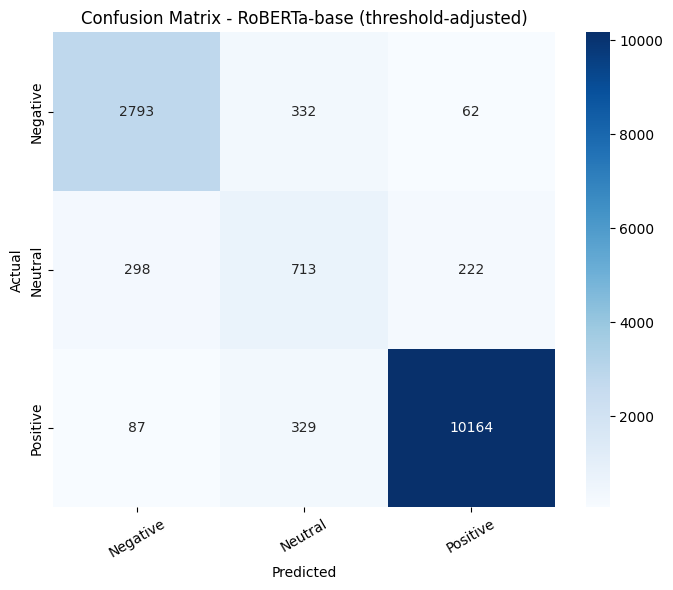

In [ ]:
# Get validation-set logits (never seen at training time in gradient updates,
# so this is a fair place to tune a decision threshold)
val_output = trainer.predict(val_ds)
val_logits = val_output.predictions
val_labels_true = val_output.label_ids

neutral_idx = label2id["Neutral"]

best_bias, best_val_f1_macro = 0.0, -1.0
bias_grid = np.arange(-2.0, 2.05, 0.1)

for bias in bias_grid:
    adjusted_logits = val_logits.copy()
    adjusted_logits[:, neutral_idx] += bias
    preds = np.argmax(adjusted_logits, axis=-1)
    _, _, f1_macro_bias, _ = precision_recall_fscore_support(
        val_labels_true, preds, average="macro", zero_division=0
    )
    if f1_macro_bias > best_val_f1_macro:
        best_val_f1_macro = f1_macro_bias
        best_bias = bias

print(f"Best Neutral logit bias (chosen on validation set): {best_bias:.2f}")
print(f"Validation macro-F1 with this bias: {best_val_f1_macro:.4f}")

# Apply the SAME bias (chosen only on validation) to the test set
test_logits_adjusted = test_logits.copy()
test_logits_adjusted[:, neutral_idx] += best_bias
test_preds_adjusted = np.argmax(test_logits_adjusted, axis=-1)

print("\nClassification report (RoBERTa-base, threshold-adjusted):")
print(
    classification_report(
        test_labels,
        test_preds_adjusted,
        target_names=[id2label[i] for i in range(NUM_LABELS)],
        zero_division=0,
    )
)

# Confusion matrix after threshold adjustment - compare against the argmax
# version above to see how many Neutral/Positive and Neutral/Negative
# confusions were resolved
cm_adjusted = confusion_matrix(test_labels, test_preds_adjusted)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_adjusted,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[id2label[i] for i in range(NUM_LABELS)],
    yticklabels=[id2label[i] for i in range(NUM_LABELS)],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RoBERTa-base (threshold-adjusted)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### 9.12 Comparing RoBERTa-base with the classical ML baseline

We compare on the same test set to confirm the transformer actually adds
value worth the extra compute/time. If a classical model (e.g. TF-IDF +
LogisticRegression) was trained earlier in the notebook, run it on the same
`test_df["review_classical"]` and compute the same metrics.

In [ ]:
# Note: this cell assumes a classical model (e.g. logistic_reg) was already
# fit on TF-IDF features earlier in the notebook, and that a fitted
# tfidf_vectorizer is available. If that part hasn't been run yet, skip this
# cell and come back to it after training the baseline.

try:
    X_test_tfidf = tfidf_vectorizer.transform(test_df["review_classical"])
    baseline_preds = logistic_reg.predict(X_test_tfidf)

    baseline_f1 = f1_score(test_df["label"], baseline_preds, average="macro")
    baseline_acc = accuracy_score(test_df["label"], baseline_preds)

    roberta_f1 = test_output.metrics["test_f1_macro"]
    roberta_acc = test_output.metrics["test_accuracy"]

    comparison_df = pd.DataFrame(
        {
            "Model": ["TF-IDF + Logistic Regression", "RoBERTa-base (fine-tuned)"],
            "Accuracy": [baseline_acc, roberta_acc],
            "Macro F1": [baseline_f1, roberta_f1],
        }
    )
    print(comparison_df)
except NameError:
    print(
        "The classical model (tfidf_vectorizer / logistic_reg) isn't defined yet. "
        "Train the baseline first, then re-run this cell."
    )


### 9.13 Saving the fine-tuned model and tokenizer

In [ ]:
SAVE_DIR = "./roberta-beauty-sentiment-final"

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

print(f"Model and tokenizer saved to: {SAVE_DIR}")


### 9.14 Quick inference example

A simple sanity check to confirm the model works correctly on a new
sentence before deploying it.

In [ ]:
from transformers import pipeline

sentiment_pipeline = pipeline(
    "text-classification",
    model=SAVE_DIR,
    tokenizer=SAVE_DIR,
    device=0 if torch.cuda.is_available() else -1,
)

sample_reviews = [
    "This product is amazing, my skin feels so much better after just one week!",
    "Terrible, it broke my skin out and the packaging was damaged.",
    "It's okay, does the job but nothing special.",
]

for review in sample_reviews:
    result = sentiment_pipeline(review, truncation=True, max_length=MAX_LENGTH)
    print(f"{review!r}\n  -> {result}\n")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

'This product is amazing, my skin feels so much better after just one week!'
  -> [{'label': 'Positive', 'score': 0.9390498995780945}]

'Terrible, it broke my skin out and the packaging was damaged.'
  -> [{'label': 'Negative', 'score': 0.8687441349029541}]

"It's okay, does the job but nothing special."
  -> [{'label': 'Neutral', 'score': 0.7407921552658081}]

